In [8]:
import numpy as np
import pandas as pd

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
file_path = '/content/nhamcs_data_2018_22.csv'
ER = pd.read_csv(file_path)
ER.head()

,visit_month,day_of_week,arrival_time,ems_arrival,vitals_during_visit,age,residence,sex,insurance,no_payment,...,hist_sleep_apnea,hist_osteoporosis,hist_substance_abuse,intervention_iv_fluids,target_triage_acuity,wait_time_minutes,race,year,chief_complaint_text,injury_cause_text
0,12,1,2046.0,No,1.0,5,Private residence,Male,Unknown/Blank,0,...,0,0,0,0,4,21.0,Unknown/Other,2018,fever. throat soreness,Blank/Unknown
1,12,1,1907.0,No,1.0,5,Private residence,Female,Unknown/Blank,0,...,0,0,0,0,4,12.0,Unknown/Other,2018,"injury, other and unspecified, of foo.... foot...",other foreign body or object entering through ...
2,12,6,1435.0,No,1.0,0,Unknown,Male,Unknown/Blank,0,...,0,0,0,0,4,21.0,Unknown/Other,2018,fever. cough,Blank/Unknown
3,12,4,1736.0,No,2.0,21,Private residence,Female,Unknown/Blank,0,...,0,0,0,0,4,59.0,Hispanic,2018,"abdominal pain, cramps, spasms. chest pain. po...",Blank/Unknown
4,11,2,1718.0,No,2.0,26,Private residence,Female,Private,0,...,0,0,0,0,4,25.0,White,2018,"injury, other and unspecified, of foo...",overexertion from prolonged static or awkward ...


[알림] 기존 메모리에 로드된 'ER' DataFrame을 그대로 사용합니다.

 [1~2단계] 데이터 크기, 변수명 및 데이터 타입 확인
1. 데이터 행(환자 수) 및 열(변수 개수): 58,124행 x 49열
2. 전체 변수 목록(49개):
['visit_month', 'day_of_week', 'arrival_time', 'ems_arrival', 'vitals_during_visit', 'age', 'residence', 'sex', 'insurance', 'no_payment', 'region', 'temp', 'heart_rate', 'resp_rate', 'sys_bp', 'dias_bp', 'spo2', 'pain_score', 'seen_last_72h', 'episode', 'is_injury_poison', 'hist_alzheimers', 'hist_asthma', 'hist_cancer', 'hist_stroke', 'hist_ckd', 'hist_copd', 'hist_chf', 'hist_cad', 'hist_depression', 'hist_diabetes_t1', 'hist_diabetes_t2', 'hist_diabetes_unspec', 'hist_esrd', 'hist_pe', 'hist_hiv', 'hist_high_cholesterol', 'hist_hypertension', 'hist_obesity', 'hist_sleep_apnea', 'hist_osteoporosis', 'hist_substance_abuse', 'intervention_iv_fluids', 'target_triage_acuity', 'wait_time_minutes', 'race', 'year', 'chief_complaint_text', 'injury_cause_text']

[3단계] 변수별 데이터 타입 및 결측치 요약표 (결측 비율 상위 15개):


,데이터 타입(Dtype),결측치 개수(Missing),결측치 비율(%),고유값 개수(Unique)
pain_score,float64,14805,25.47,11
wait_time_minutes,float64,6700,11.53,554
dias_bp,float64,5199,8.94,149
sys_bp,float64,5152,8.86,209
seen_last_72h,float64,2682,4.61,2
spo2,float64,2202,3.79,76
temp,float64,2045,3.52,145
is_injury_poison,object,1857,3.19,5
heart_rate,float64,1649,2.84,210
resp_rate,float64,1582,2.72,113



[4단계] 완전히 동일한 중복 행 개수: 5건 (0.01%)

[5단계] 주요 수치형 변수(연령, 대기시간, 활력징후) 기술통계량:


,count,mean,std,min,25%,50%,75%,max
age,58124.0,39.70,24.60,0.0,20.0,38.0,59.0,94.0
wait_time_minutes,51424.0,33.44,62.37,0.0,5.0,14.0,35.0,1440.0
temp,56079.0,98.31,1.01,84.0,97.8,98.2,98.6,109.9
heart_rate,56475.0,92.97,39.22,0.0,77.0,88.0,103.0,998.0
resp_rate,56542.0,19.47,6.17,0.0,16.0,18.0,20.0,150.0
sys_bp,52972.0,134.90,24.40,0.0,118.0,132.0,149.0,289.0
dias_bp,52925.0,79.51,24.92,0.0,69.0,78.0,88.0,998.0
spo2,55922.0,97.42,5.47,0.0,97.0,98.0,99.0,100.0
pain_score,43319.0,4.45,3.72,0.0,0.0,5.0,8.0,10.0



[6단계] 주요 범주형 변수 빈도 및 비율 요약:

▶ 변수명: sex


,빈도(명),비율(%)
sex,,
Female,31086,53.48
Male,27038,46.52


... (4 outputs left out)


▶ 변수명: ems_arrival


,빈도(명),비율(%)
ems_arrival,,
No,46588,80.15
Yes,10218,17.58
Unknown,983,1.69
Blank,335,0.58



▶ 변수명: target_triage_acuity


,빈도(명),비율(%)
target_triage_acuity,,
3,29568,50.87
4,16715,28.76
2,8597,14.79
5,2398,4.13
1,846,1.46


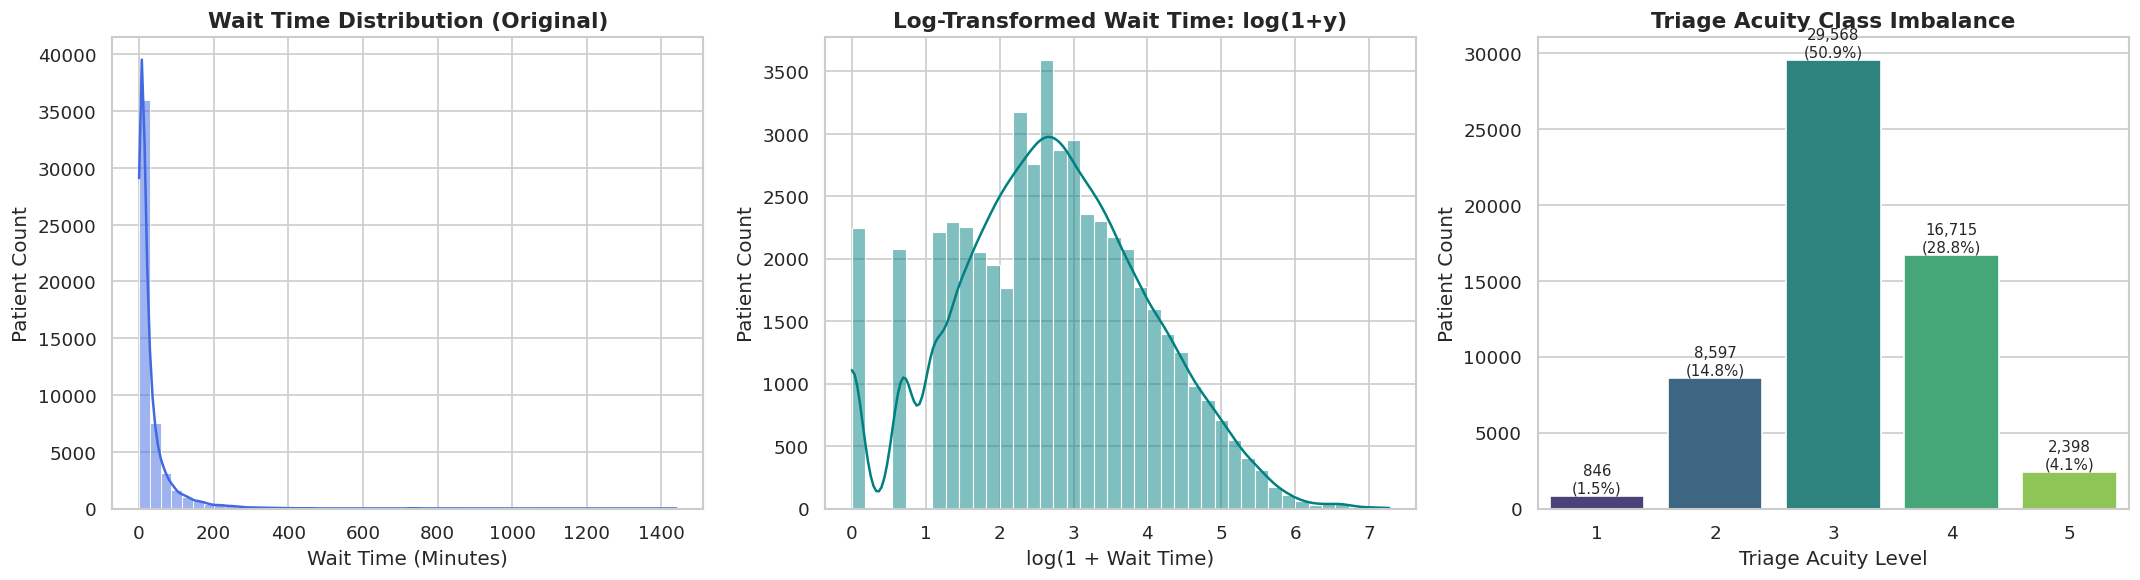


[8단계] 수치형 변수별 사분위수 범위(IQR) 기준 이상치 탐색:


,변수명,Q1(25%),Median(50%),Q3(75%),하한선,상한선,이상치 개수,이상치 비율(%)
0,age,20.0,38.0,59.0,-38.5,117.5,0,0.00
1,wait_time_minutes,5.0,14.0,35.0,-40.0,80.0,5276,10.26
2,temp,97.8,98.2,98.6,96.6,99.8,3988,7.11
3,heart_rate,77.0,88.0,103.0,38.0,142.0,2180,3.86
4,resp_rate,16.0,18.0,20.0,10.0,26.0,3598,6.36
5,sys_bp,118.0,132.0,149.0,71.5,195.5,1028,1.94
6,dias_bp,69.0,78.0,88.0,40.5,116.5,851,1.61
7,spo2,97.0,98.0,99.0,94.0,102.0,2740,4.90
8,pain_score,0.0,5.0,8.0,-12.0,20.0,0,0.00


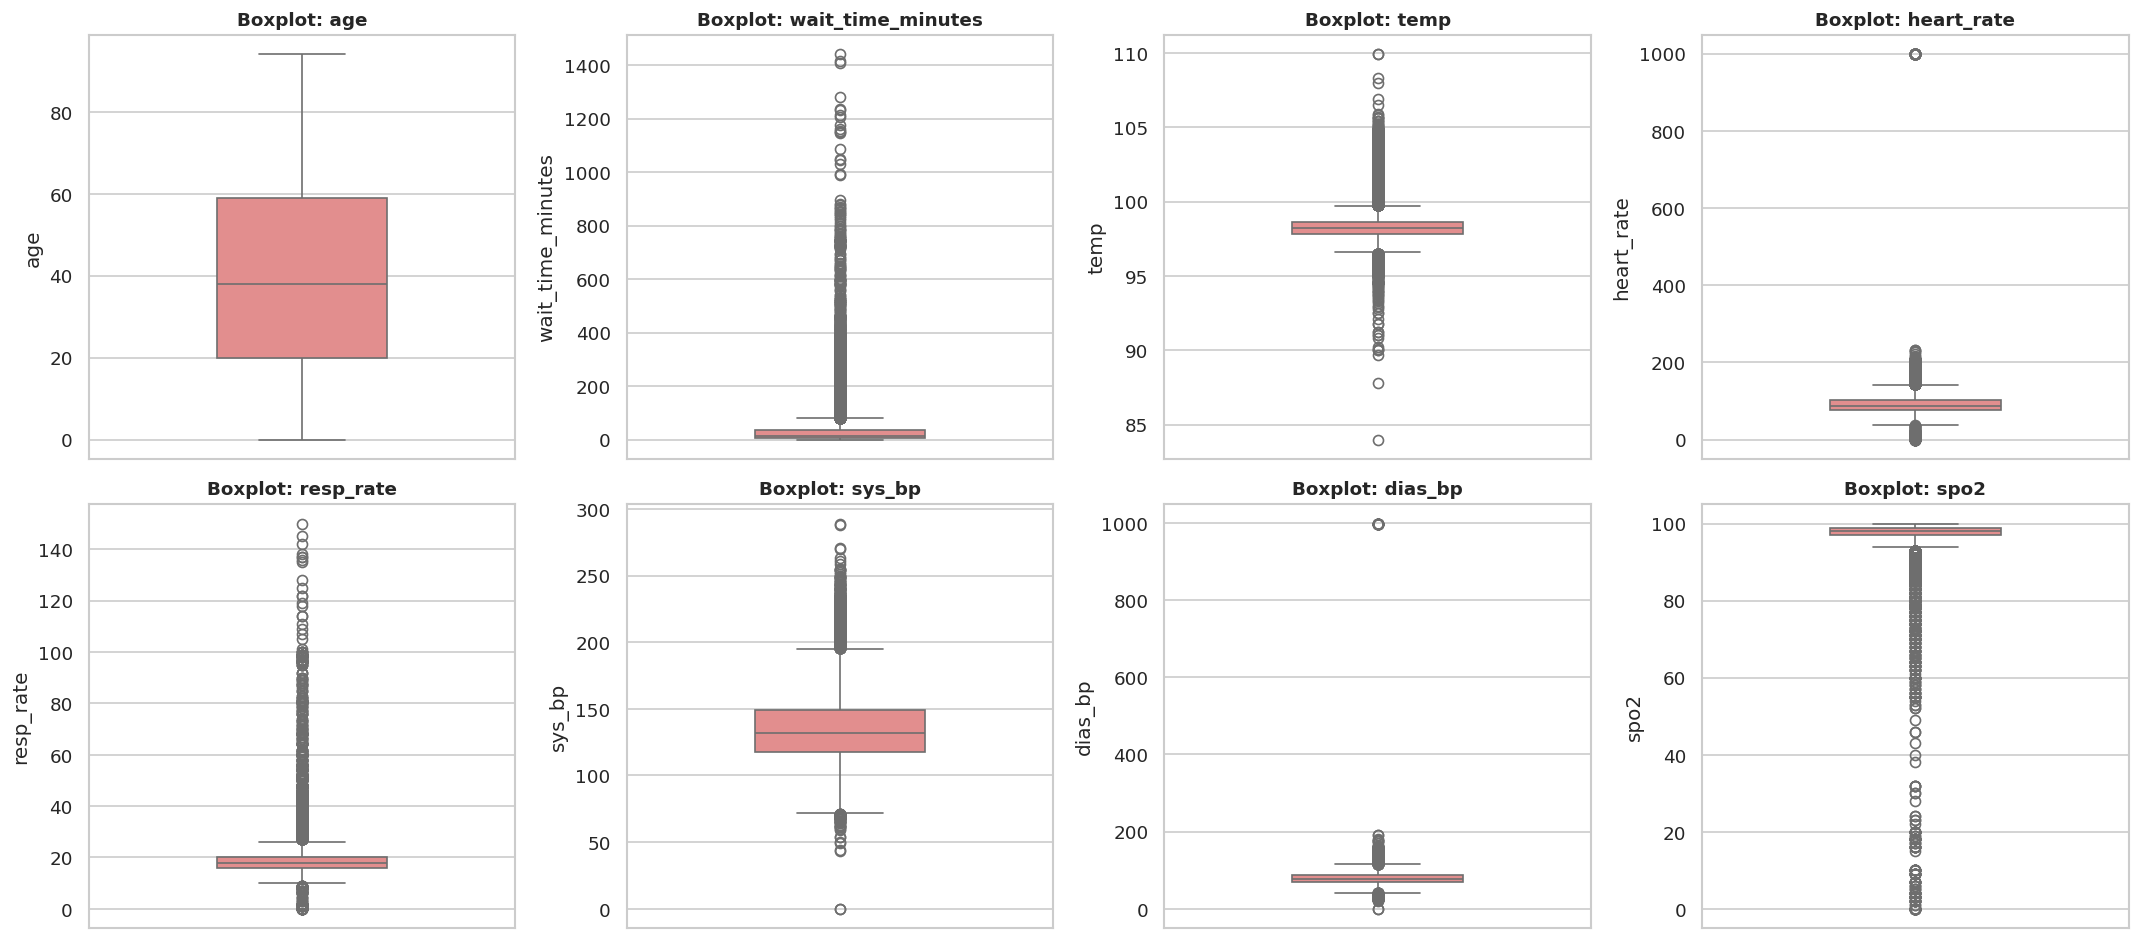


[10단계] 주요 수치형 변수 및 타겟 변수 간 피어슨 상관계수 히트맵:


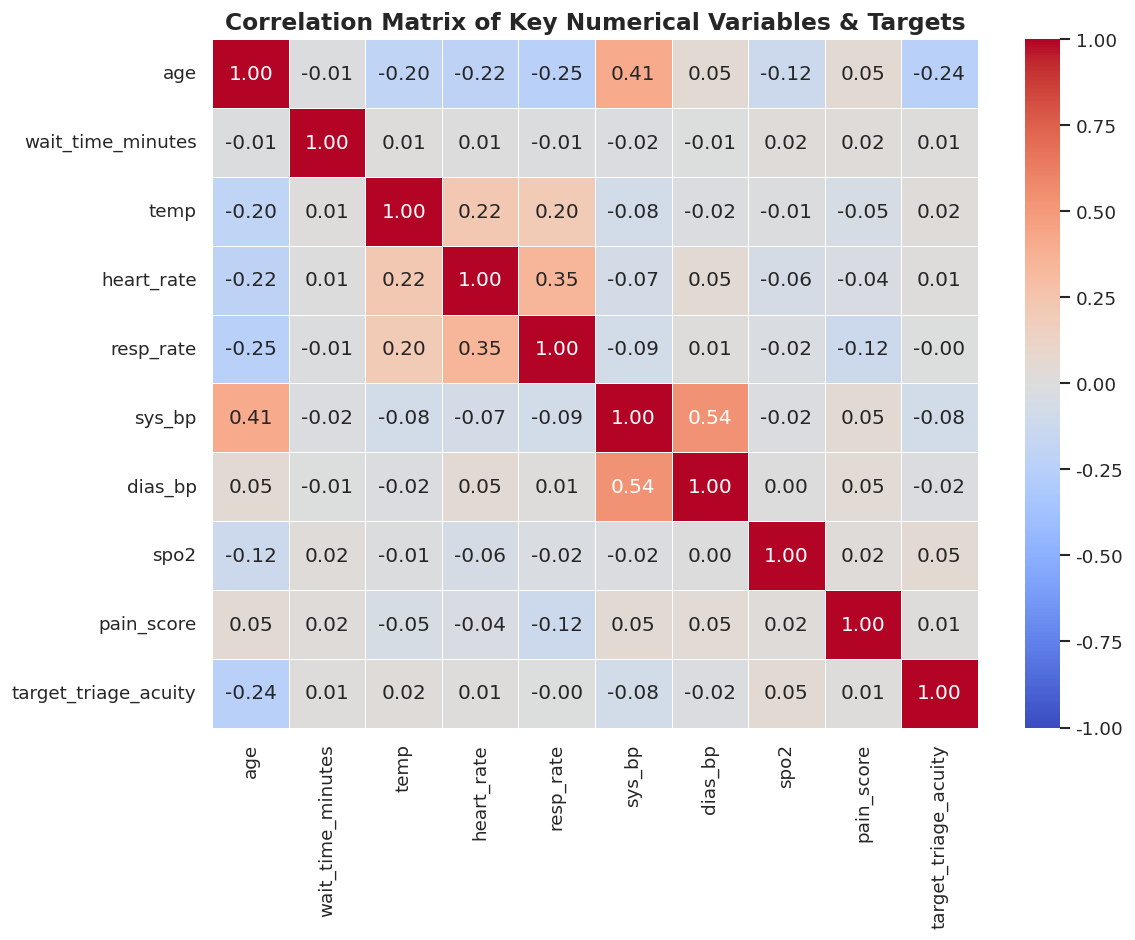


 [분석 A] 응급실 대기시간(wait_time_minutes) 예측 회귀분석 시작
▶ 분석 A 학습 데이터: 41,139건 / 테스트 데이터: 10,285건
완료: 1. Linear Regression         | MAE: 32.03 | RMSE: 60.95 | R2: 0.0226
완료: 2. Ridge Regression          | MAE: 32.03 | RMSE: 60.95 | R2: 0.0226
완료: 3. Lasso Regression          | MAE: 32.09 | RMSE: 61.02 | R2: 0.0201
완료: 4. Random Forest Regressor   | MAE: 31.96 | RMSE: 60.65 | R2: 0.0321
완료: 5. XGBoost Regressor         | MAE: 31.79 | RMSE: 60.41 | R2: 0.0396
완료: 6. CatBoost Regressor        | MAE: 31.50 | RMSE: 60.12 | R2: 0.0490

[분석 A 결과물 1] 회귀 모델별 성능 비교표 (RMSE 기준 오름차순 정렬):


,Model,MAE (분),RMSE (분),R2 Score
0,6. CatBoost Regressor,31.498,60.118,0.0490
1,5. XGBoost Regressor,31.789,60.413,0.0396
2,4. Random Forest Regressor,31.959,60.649,0.0321
3,1. Linear Regression,32.026,60.947,0.0226
4,2. Ridge Regression,32.026,60.947,0.0226
5,3. Lasso Regression,32.092,61.024,0.0201


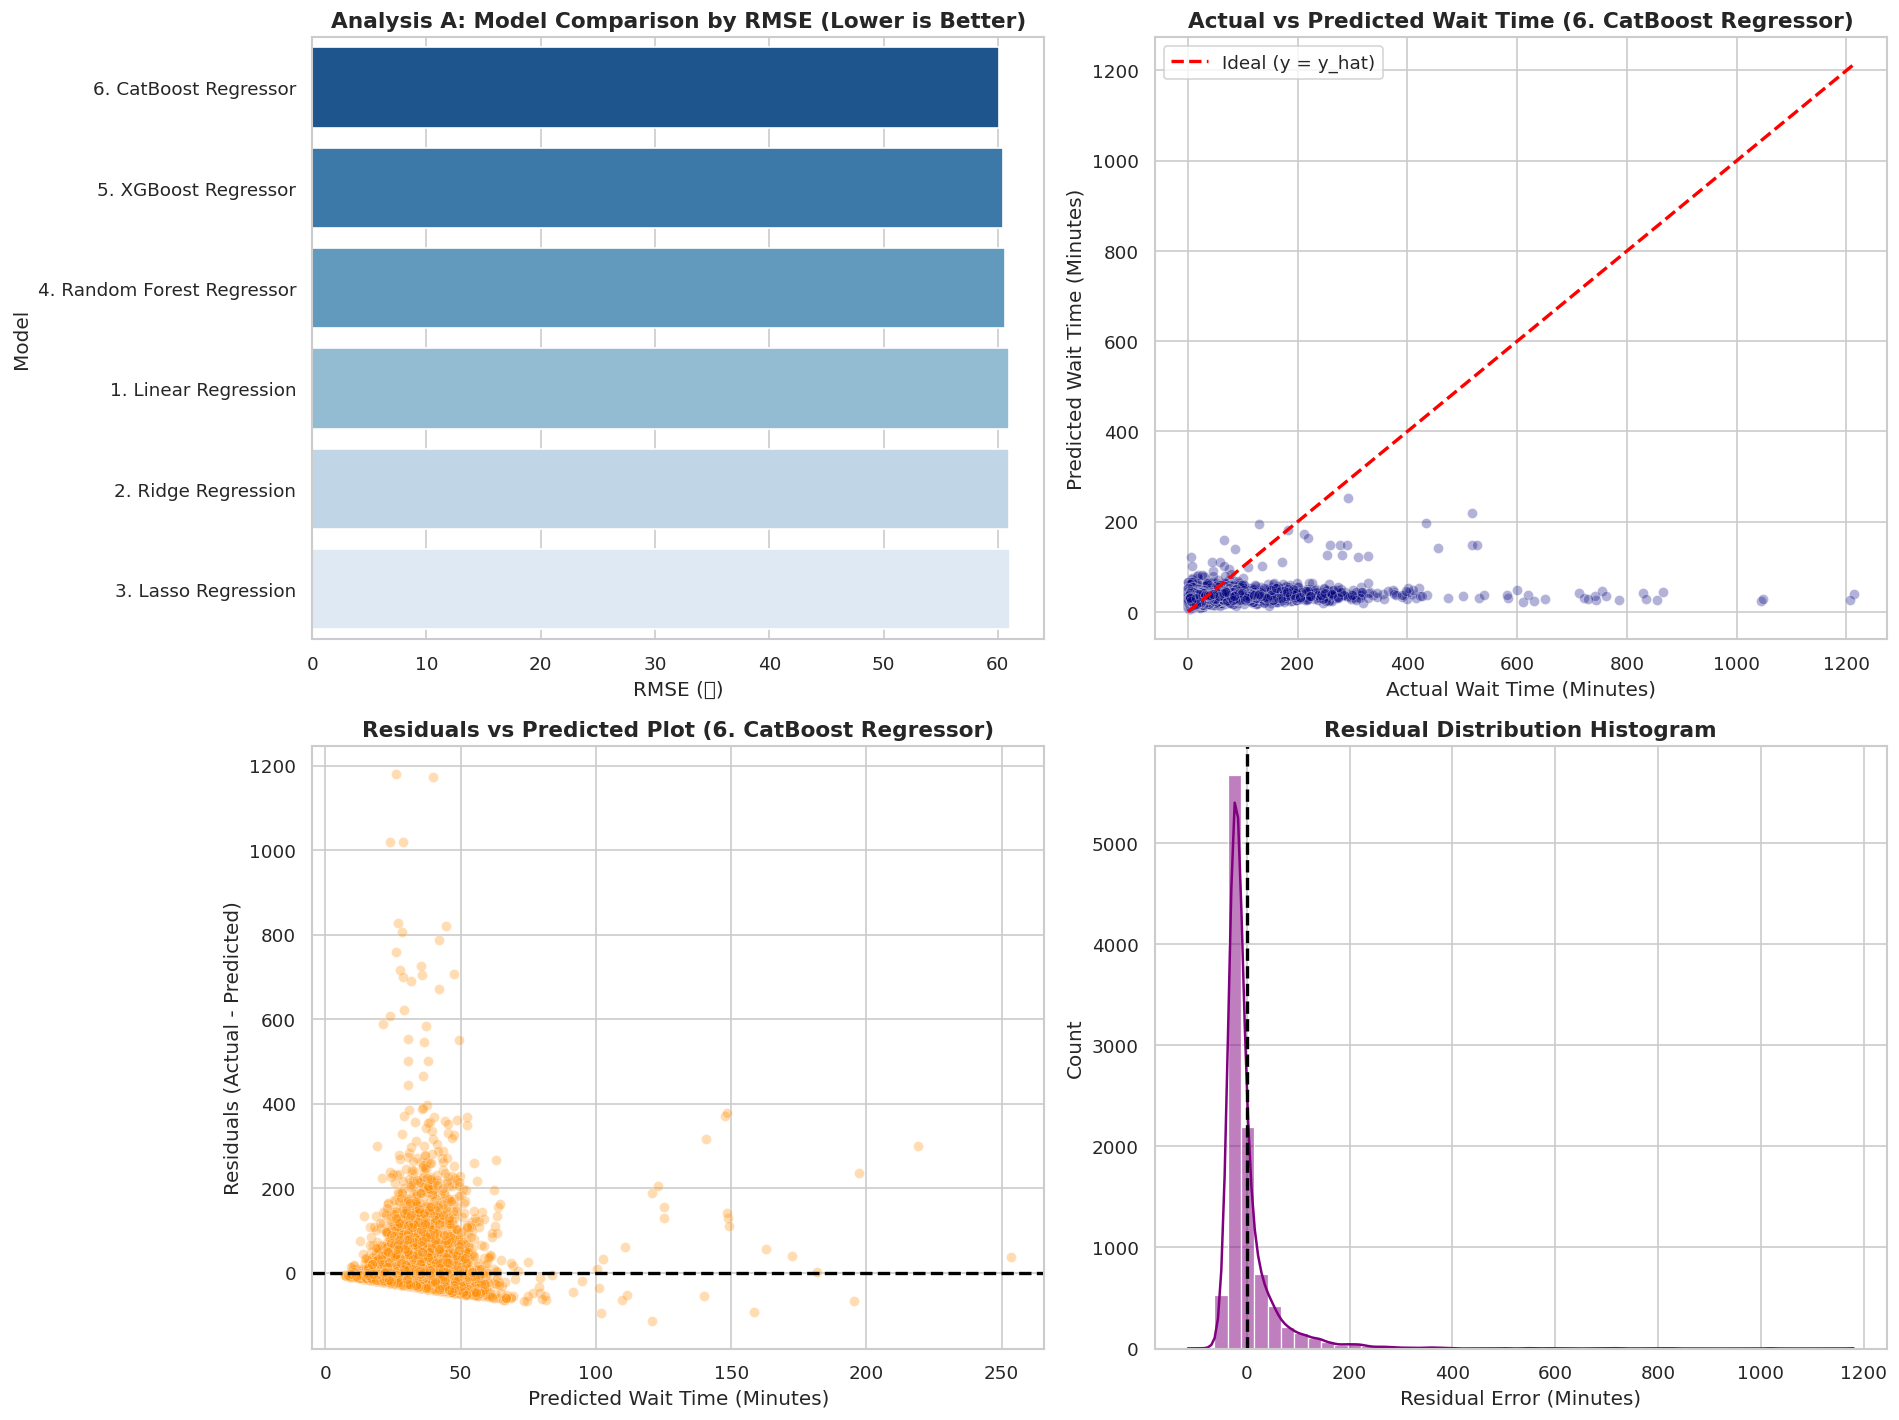


 [분석 B] 응급실 중증도(target_triage_acuity) 예측 분류분석 시작
▶ 분석 B 학습 데이터: 46,499건 / 테스트 데이터: 11,625건
▶ 분류 대상 응급도 등급(Classes): ['1', '2', '3', '4', '5']
완료: 1. Logistic Regression         | Macro F1: 0.3103 | Bal_Acc: 0.4133 | Kappa: 0.3092
  [참고] OrderedModel 수치 수렴 보정을 위해 L2 정규화 대체 적합 수행: There should not be a constant in the model
완료: 2. Ordinal Logistic Regression | Macro F1: 0.2373 | Bal_Acc: 0.3210 | Kappa: 0.2161
완료: 3. Decision Tree Classifier    | Macro F1: 0.2831 | Bal_Acc: 0.3713 | Kappa: 0.3191
완료: 4. Random Forest Classifier    | Macro F1: 0.3599 | Bal_Acc: 0.4138 | Kappa: 0.3838
완료: 5. XGBoost Classifier          | Macro F1: 0.3652 | Bal_Acc: 0.4561 | Kappa: 0.3913
완료: 6. CatBoost Classifier         | Macro F1: 0.3430 | Bal_Acc: 0.4460 | Kappa: 0.3646

[분석 B 결과물 1] 분류 모델별 성능 비교표 (Macro F1 기준 내림차순 정렬):


,Model,Accuracy,Precision (Macro),Recall (Macro),Macro F1,Balanced Acc,Weighted Kappa
0,5. XGBoost Classifier,0.4621,0.3638,0.4561,0.3652,0.4561,0.3913
1,4. Random Forest Classifier,0.4677,0.3586,0.4138,0.3599,0.4138,0.3838
2,6. CatBoost Classifier,0.4326,0.3555,0.4460,0.3430,0.4460,0.3646
3,1. Logistic Regression,0.3910,0.3402,0.4133,0.3103,0.4133,0.3092
4,3. Decision Tree Classifier,0.3612,0.3162,0.3713,0.2831,0.3713,0.3191
5,2. Ordinal Logistic Regression,0.2935,0.2687,0.3210,0.2373,0.3210,0.2161


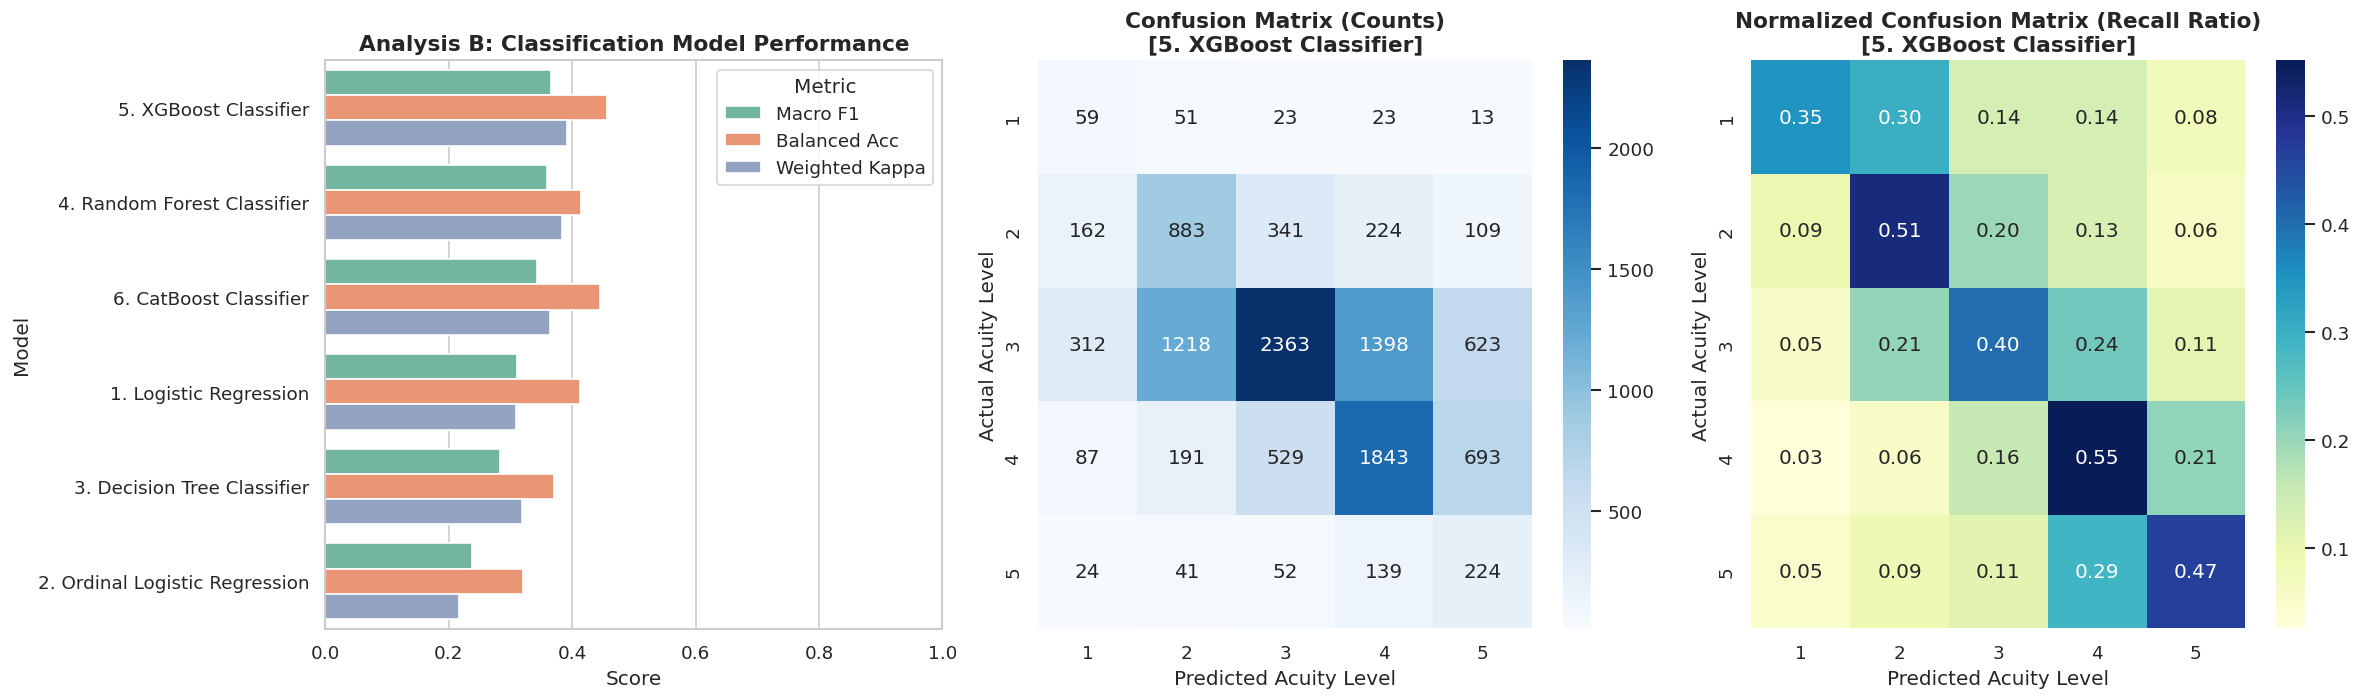


 [STEP 6] 변수 중요도(Feature Importance) 및 SHAP 심층 해석

[분석 A 해석 대상 모델]: 6. CatBoost Regressor


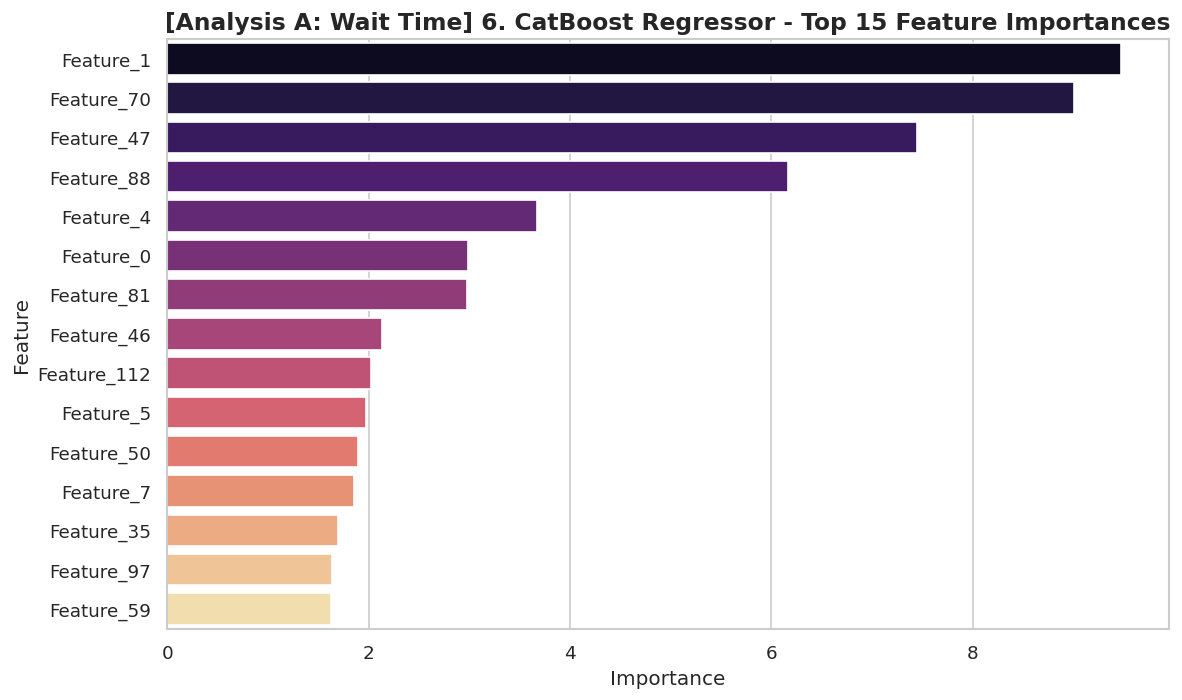


▶ [Analysis A: Wait Time] 6. CatBoost Regressor 상위 10개 핵심 중요 변수 표:


,Feature,Importance
0,Feature_1,9.471562
1,Feature_70,9.005496
2,Feature_47,7.446041
3,Feature_88,6.162938
4,Feature_4,3.672411
5,Feature_0,2.981732
6,Feature_81,2.977023
7,Feature_46,2.130819
8,Feature_112,2.020555
9,Feature_5,1.971118



▶ [Analysis A: Wait Time] 6. CatBoost Regressor SHAP 값 계산 및 시각화 진행 중...


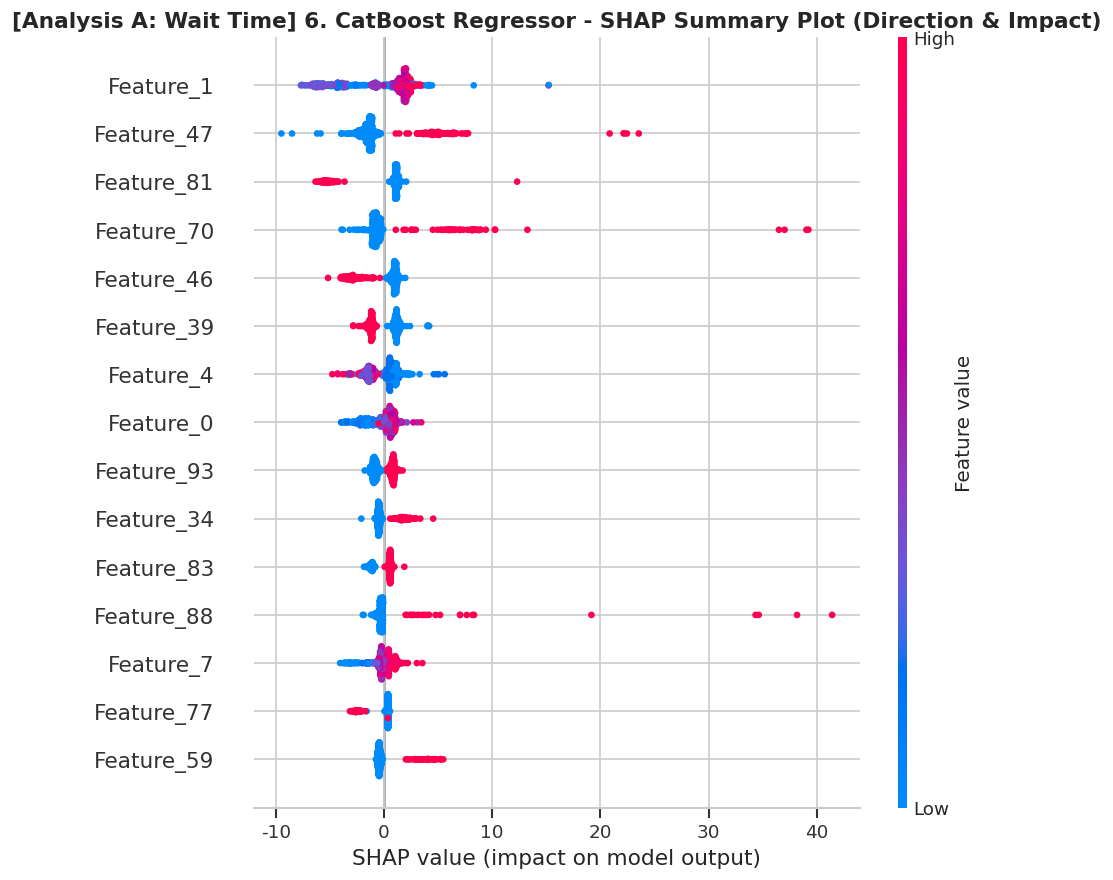

<Figure size 960x600 with 0 Axes>

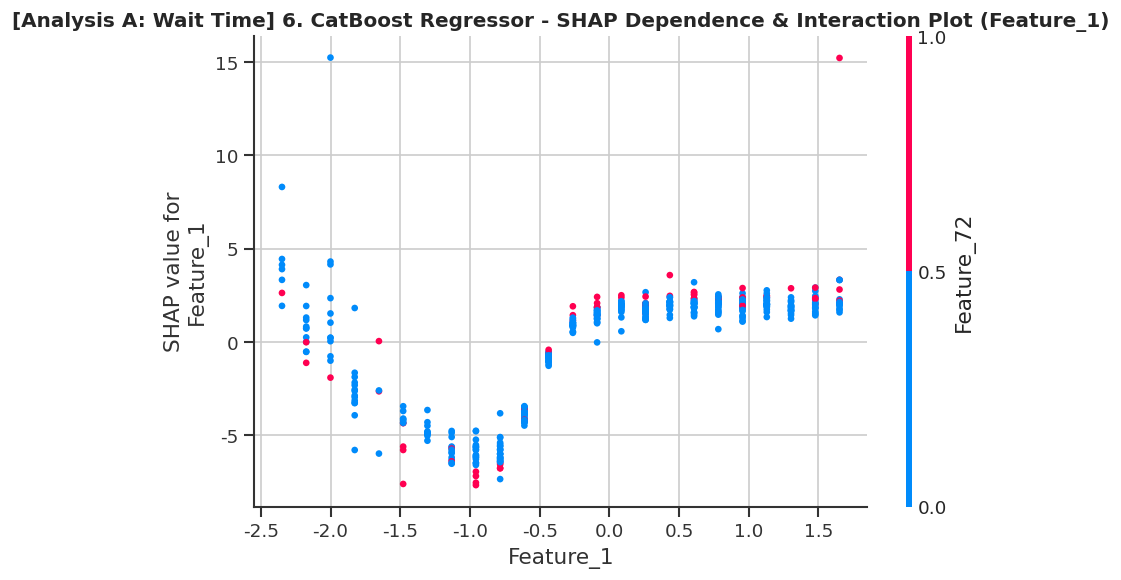


[분석 B 해석 대상 모델]: 5. XGBoost Classifier


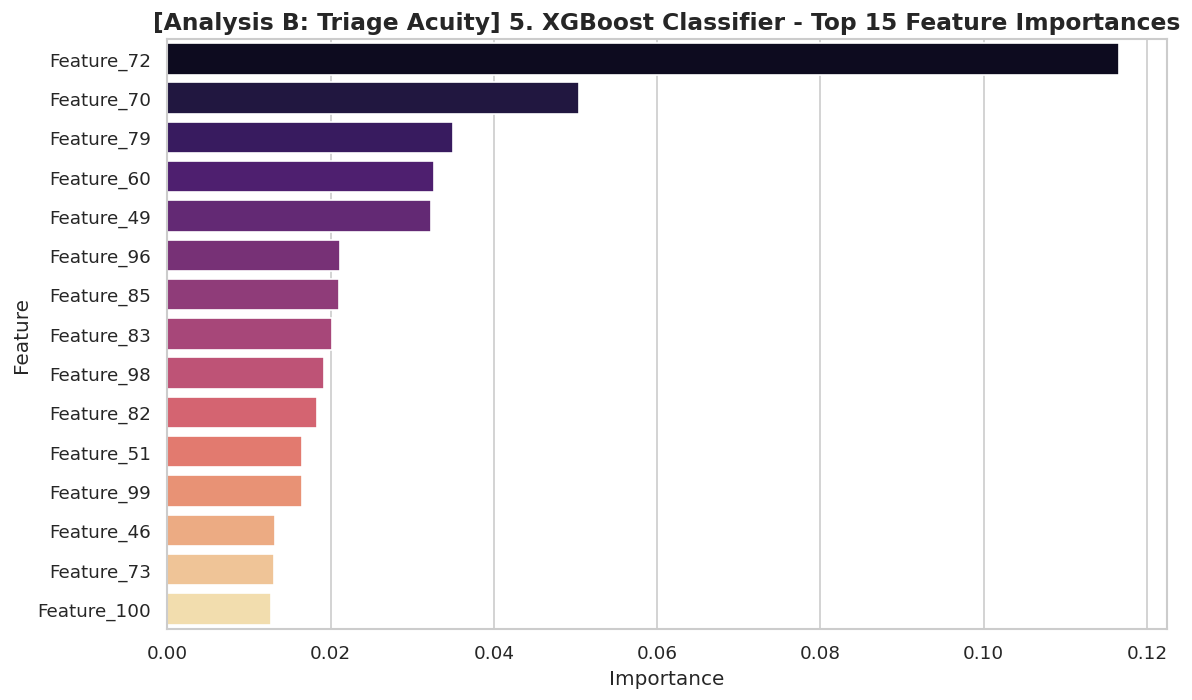


▶ [Analysis B: Triage Acuity] 5. XGBoost Classifier 상위 10개 핵심 중요 변수 표:


,Feature,Importance
0,Feature_72,0.116633
1,Feature_70,0.050387
2,Feature_79,0.035021
3,Feature_60,0.032691
4,Feature_49,0.032345
5,Feature_96,0.021169
6,Feature_85,0.021042
7,Feature_83,0.020194
8,Feature_98,0.019215
9,Feature_82,0.018392



▶ [Analysis B: Triage Acuity] 5. XGBoost Classifier SHAP 값 계산 및 시각화 진행 중...


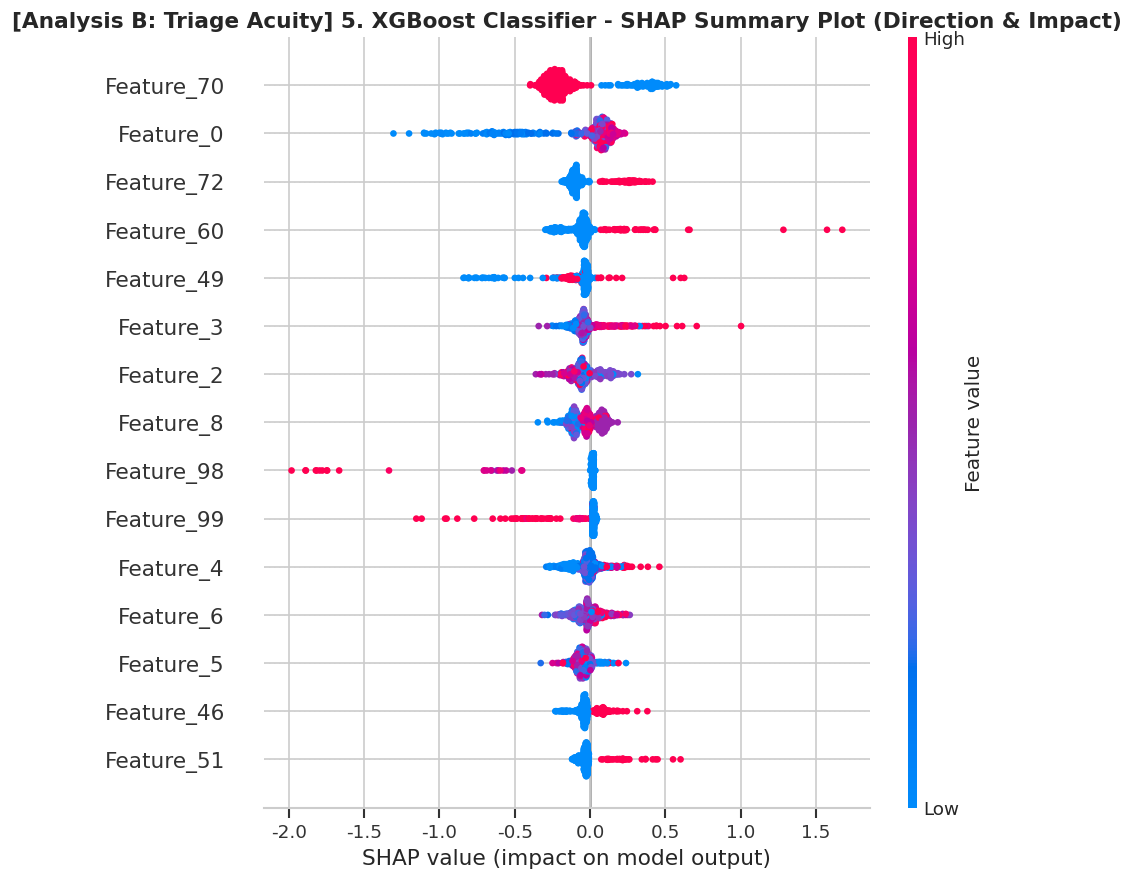

<Figure size 960x600 with 0 Axes>

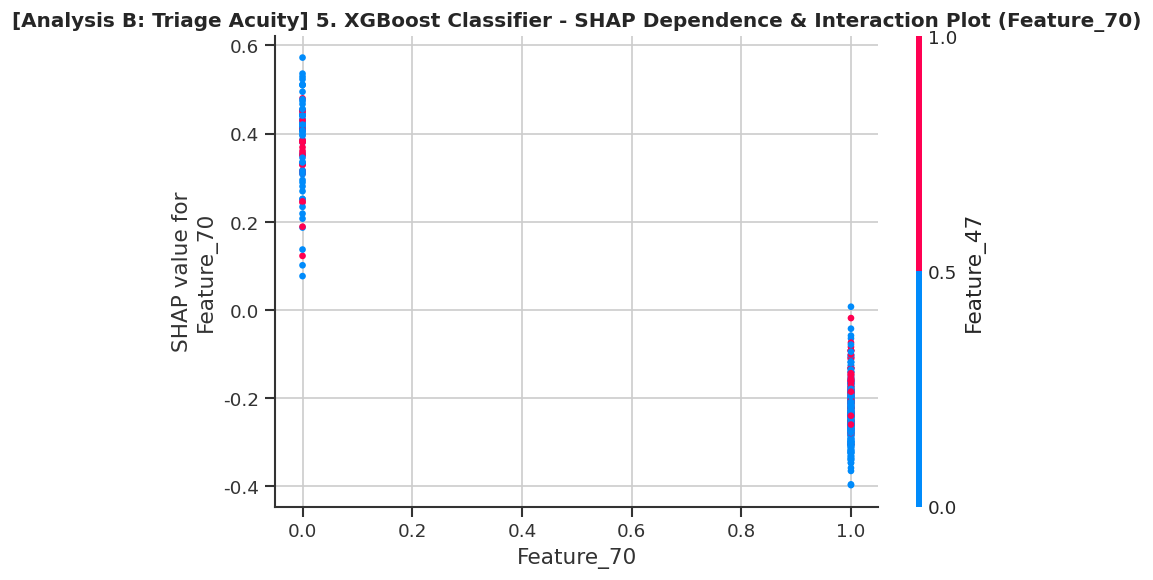


[전체 분석 파이프라인 실행이 성공적으로 완료되었습니다.]


In [12]:
# ==============================================================================
# [사전 준비] 필수 라이브러리 설치 (Colab / Jupyter Notebook 셀에서 실행)
# 이미 설치된 환경이라면 주석 처리(#) 후 진행하셔도 됩니다.
# ==============================================================================
!pip install -q numpy pandas matplotlib seaborn scipy statsmodels scikit-learn xgboost catboost shap

# ==============================================================================
# STEP 0. 라이브러리 불러오기 및 시각화 환경 설정
# ==============================================================================
import warnings
warnings.filterwarnings('ignore') # 불필요한 경고 메시지를 숨겨 출력 화면을 깔끔하게 유지합니다.

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 통계 및 머신러닝 전처리 도구 (Scikit-learn)
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_sample_weight

# 회귀분석(분석 A) 모델 및 평가지표
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 분류분석(분석 B) 모델 및 평가지표
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, cohen_kappa_score
)

# 순서형 로지스틱 회귀 (Statsmodels)
from statsmodels.miscmodels.ordinal_model import OrderedModel

# 부스팅 알고리즘 및 설명 가능한 AI (XGBoost, CatBoost, SHAP)
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor, CatBoostClassifier
import shap

# 시각화 스타일 및 운영체제별 한글 폰트 자동 설정 (그래프 깨짐 방지)
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="muted")

if os.name == 'nt': # Windows (Anaconda Jupyter)
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif os.name == 'posix': # Mac 또는 Google Colab (영문/한글 호환 처리)
    try:
        plt.rcParams['font.family'] = 'AppleGothic'
    except:
        plt.rcParams['font.family'] = 'DejaVu Sans'


# ==============================================================================
# STEP 1. 데이터 확인 및 원본 보존 (ER 유지)
# ==============================================================================
# 이미 ER이 메모리에 올라와 있다면 그대로 사용하고, 없다면 CSV 파일에서 불러옵니다.
if 'ER' not in globals():
    if os.path.exists('nhamcs_data_2018_22.csv'):
        ER = pd.read_csv('nhamcs_data_2018_22.csv')
        print("[알림] 'nhamcs_data_2018_22.csv' 파일을 성공적으로 불러왔습니다.")
    else:
        raise FileNotFoundError("현재 경로에 'nhamcs_data_2018_22.csv' 파일이 없거나 ER 변수가 선언되지 않았습니다.")
else:
    print("[알림] 기존 메모리에 로드된 'ER' DataFrame을 그대로 사용합니다.")

# 원본 ER을 절대 변경하지 않기 위해 탐색용 복사본(df_eda)을 생성합니다.
df_eda = ER.copy()


# ==============================================================================
# STEP 2. 데이터 탐색 (EDA 10단계) 및 핵심 시각화
# ==============================================================================
print("\n" + "="*80)
print(" [1~2단계] 데이터 크기, 변수명 및 데이터 타입 확인")
print("="*80)
print(f"1. 데이터 행(환자 수) 및 열(변수 개수): {df_eda.shape[0]:,}행 x {df_eda.shape[1]}열")
print(f"2. 전체 변수 목록({len(df_eda.columns)}개):\n{list(df_eda.columns)}")

dtype_df = pd.DataFrame({
    '데이터 타입(Dtype)': df_eda.dtypes.astype(str),
    '결측치 개수(Missing)': df_eda.isnull().sum(),
    '결측치 비율(%)': (df_eda.isnull().sum() / len(df_eda) * 100).round(2),
    '고유값 개수(Unique)': df_eda.nunique()
})
print("\n[3단계] 변수별 데이터 타입 및 결측치 요약표 (결측 비율 상위 15개):")
display(dtype_df.sort_values(by='결측치 비율(%)', ascending=False).head(15))

# 4. 중복 데이터 확인
dup_count = df_eda.duplicated().sum()
print(f"\n[4단계] 완전히 동일한 중복 행 개수: {dup_count:,}건 ({dup_count/len(df_eda)*100:.2f}%)")

# 변수 그룹 정의 (실제 데이터에 존재하는 변수만 안전하게 필터링)
vital_cols = [c for c in ['temp', 'heart_rate', 'resp_rate', 'sys_bp', 'dias_bp', 'spo2', 'pain_score'] if c in df_eda.columns]
hist_cols = [c for c in df_eda.columns if c.startswith('hist_')]
num_cols_eda = [c for c in ['age', 'wait_time_minutes'] + vital_cols if c in df_eda.columns]
cat_cols_eda = [c for c in ['sex', 'race', 'residence', 'region', 'insurance', 'visit_month',
                            'day_of_week', 'ems_arrival', 'is_injury_poison', 'seen_last_72h',
                            'target_triage_acuity'] if c in df_eda.columns]

# 5. 수치형 변수의 기술통계량 확인
print("\n[5단계] 주요 수치형 변수(연령, 대기시간, 활력징후) 기술통계량:")
display(df_eda[num_cols_eda].describe().T.round(2))

# 6. 범주형 변수의 빈도 및 비율 확인
print("\n[6단계] 주요 범주형 변수 빈도 및 비율 요약:")
for col in ['sex', 'race', 'insurance', 'ems_arrival', 'target_triage_acuity']:
    if col in df_eda.columns:
        freq = df_eda[col].value_counts(dropna=False)
        ratio = (df_eda[col].value_counts(dropna=False, normalize=True) * 100).round(2)
        summary_cat = pd.DataFrame({'빈도(명)': freq, '비율(%)': ratio})
        print(f"\n▶ 변수명: {col}")
        display(summary_cat)

# 7 & 9. 종속변수 분포 및 클래스 불균형 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) 대기시간 원본 분포
if 'wait_time_minutes' in df_eda.columns:
    sns.histplot(df_eda['wait_time_minutes'].dropna(), bins=50, kde=True, ax=axes[0], color='royalblue')
    axes[0].set_title('Wait Time Distribution (Original)', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Wait Time (Minutes)')
    axes[0].set_ylabel('Patient Count')

    # (2) 대기시간 로그 변환(log1p) 분포 (우측 꼬리 비대칭 확인용)
    valid_wait = df_eda['wait_time_minutes'].dropna()
    valid_wait = valid_wait[valid_wait >= 0]
    sns.histplot(np.log1p(valid_wait), bins=40, kde=True, ax=axes[1], color='teal')
    axes[1].set_title('Log-Transformed Wait Time: log(1+y)', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('log(1 + Wait Time)')
    axes[1].set_ylabel('Patient Count')

# (3) 응급도 등급(target_triage_acuity) 분포 및 클래스 불균형 확인
if 'target_triage_acuity' in df_eda.columns:
    triage_counts = df_eda['target_triage_acuity'].value_counts().sort_index()
    sns.barplot(x=triage_counts.index.astype(str), y=triage_counts.values, ax=axes[2], palette='viridis')
    axes[2].set_title('Triage Acuity Class Imbalance', fontsize=13, fontweight='bold')
    axes[2].set_xlabel('Triage Acuity Level')
    axes[2].set_ylabel('Patient Count')
    for i, v in enumerate(triage_counts.values):
        axes[2].text(i, v, f"{v:,}\n({v/triage_counts.sum()*100:.1f}%)", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# 8. 수치형 변수의 이상치(Outlier) IQR 기준 산출 및 박스플롯 시각화
print("\n[8단계] 수치형 변수별 사분위수 범위(IQR) 기준 이상치 탐색:")
outlier_summary = []
for col in num_cols_eda:
    series = pd.to_numeric(df_eda[col], errors='coerce').dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    outlier_summary.append({
        '변수명': col,
        'Q1(25%)': round(q1, 2),
        'Median(50%)': round(series.median(), 2),
        'Q3(75%)': round(q3, 2),
        '하한선': round(lower_bound, 2),
        '상한선': round(upper_bound, 2),
        '이상치 개수': len(outliers),
        '이상치 비율(%)': round(len(outliers) / len(series) * 100, 2)
    })
display(pd.DataFrame(outlier_summary))

# 수치형 변수 이상치 Boxplot 시각화
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for idx, col in enumerate(num_cols_eda[:8]):
    sns.boxplot(y=pd.to_numeric(df_eda[col], errors='coerce'), ax=axes[idx], color='lightcoral', width=0.4)
    axes[idx].set_title(f'Boxplot: {col}', fontsize=11, fontweight='bold')
for idx in range(len(num_cols_eda[:8]), 8):
    axes[idx].axis('off')
plt.tight_layout()
plt.show()

# 10. 변수 간 상관관계 히트맵(Heatmap) 확인
print("\n[10단계] 주요 수치형 변수 및 타겟 변수 간 피어슨 상관계수 히트맵:")
corr_cols = [c for c in num_cols_eda + ['target_triage_acuity'] if c in df_eda.columns]
corr_df = df_eda[corr_cols].apply(pd.to_numeric, errors='coerce').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Key Numerical Variables & Targets", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# ==============================================================================
# STEP 3. 데이터 누수 없는 커스텀 전처리 함수 및 파이프라인 빌더 설계
# ==============================================================================
def extract_arrival_hour(df_in):
    """
    arrival_time 변수가 '14:30', '1430', 또는 숫자 형태 등 어떤 포맷으로 들어와도
    안전하게 0~23시(Hour) 수치형 변수로 변환하는 함수입니다.
    """
    df_out = df_in.copy()
    if 'arrival_time' in df_out.columns:
        def parse_hour(val):
            if pd.isna(val):
                return np.nan
            s = str(val).strip()
            # '14:30' 형태 처리
            if ':' in s:
                try:
                    return float(s.split(':')[0])
                except:
                    return np.nan
            # 숫자만 추출하여 1430 -> 14시, 930 -> 9시 변환
            nums = re.findall(r'\d+', s)
            if nums:
                num_val = int(nums[0])
                if 0 <= num_val <= 23:
                    return float(num_val)
                elif 24 <= num_val <= 2400:
                    return float(num_val // 100)
            return np.nan
        df_out['arrival_time'] = df_out['arrival_time'].apply(parse_hour)
    return df_out

def clean_clinical_bounds(df_in):
    """
    응급실 데이터에서 고혈압/빈맥 등 실제 위중 환자의 극단치는 보존하되,
    측정 오류이거나 음수 코드(-9, -8 등 NHAMCS 결측 코드)만 NaN으로 정제합니다.
    """
    df_out = df_in.copy()
    bounds = {
        'age': (0, 120),
        'temp': (25.0, 45.0),       # 섭씨 기준 (화씨일 경우 자동 감지 위해 아래 조건 적용)
        'heart_rate': (10, 300),
        'resp_rate': (2, 80),
        'sys_bp': (30, 300),
        'dias_bp': (10, 200),
        'spo2': (30, 100),
        'pain_score': (0, 10)
    }
    for col, (low, high) in bounds.items():
        if col in df_out.columns:
            s = pd.to_numeric(df_out[col], errors='coerce')
            # 만약 체온(temp) 중앙값이 80 이상이면 화씨(Fahrenheit) 데이터이므로 화씨 범위(77~113F) 적용
            if col == 'temp' and s.median() > 80:
                s = s.where((s >= 77.0) & (s <= 113.0), np.nan)
            else:
                s = s.where((s >= low) & (s <= high), np.nan)
            df_out[col] = s
    return df_out

def build_preprocessor(X_sample):
    """
    입력 데이터프레임 X_sample의 컬럼 구성에 맞춰
    수치형, 범주형, 텍스트(주호소) 변수를 분리 처리하는 ColumnTransformer를 반환합니다.
    """
    # 1. 텍스트 변수 (chief_complaint_text)
    text_cols = [c for c in ['chief_complaint_text'] if c in X_sample.columns]

    # 2. 수치형 변수 (활력징후, 연령, 도착 시각, 과거 병력 0/1 플래그)
    candidate_num = ['age', 'arrival_time'] + vital_cols + hist_cols
    num_cols = [c for c in candidate_num if c in X_sample.columns]

    # 3. 범주형 변수 (성별, 인종, 거주지, 지역, 보험, 내원 월/요일, 구급차 여부 등)
    cat_cols = [c for c in X_sample.columns if c not in text_cols + num_cols]

    # 수치형 파이프라인: 중앙값(Median) 결측 대체 후 표준화(StandardScaler)
    num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # 범주형 파이프라인: 문자열 통일 -> 최빈값/Missing 대체 -> 원-핫 인코딩
    cat_pipeline = Pipeline([
        ('to_str', FunctionTransformer(lambda x: x.astype(str), feature_names_out='one-to-one')),
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    transformers = [
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]

    # 텍스트 변수가 존재할 경우 TF-IDF 상위 25개 핵심 단어 피처 추출 파이프라인 추가
    if len(text_cols) > 0:
        text_pipeline = Pipeline([
            ('filler', FunctionTransformer(
                lambda x: x.iloc[:, 0].fillna('').astype(str) if isinstance(x, pd.DataFrame) else pd.Series(x[:, 0]).fillna('').astype(str)
            )),
            ('tfidf', TfidfVectorizer(max_features=25, stop_words='english'))
        ])
        transformers.append(('txt', text_pipeline, text_cols))

    preprocessor = ColumnTransformer(transformers=transformers, remainder='drop', sparse_threshold=0.0)
    return preprocessor


# ==============================================================================
# STEP 4. 분석 A: 응급실 대기시간 예측 (회귀분석 - 6개 모델 비교)
# ==============================================================================
print("\n" + "="*80)
print(" [분석 A] 응급실 대기시간(wait_time_minutes) 예측 회귀분석 시작")
print("="*80)

# 원본 보존을 위해 별도의 DataFrame(df_a) 생성
df_a = ER.copy()
df_a = extract_arrival_hour(df_a)
df_a = clean_clinical_bounds(df_a)

# 종속변수(wait_time_minutes) 결측치 및 음수 오류 제거 (0분 이상~1440분(24시간) 이하 유효 대기시간 필터링)
df_a['wait_time_minutes'] = pd.to_numeric(df_a['wait_time_minutes'], errors='coerce')
df_a = df_a[df_a['wait_time_minutes'].notna() & (df_a['wait_time_minutes'] >= 0) & (df_a['wait_time_minutes'] <= 1440)].copy()

# 독립변수 후보 선정 (대기시간 이후 발생하는 사후 변수 intervention_iv_fluids, episode 등은 제외)
# ※ target_triage_acuity는 최초 내원 직후 분류 시점에 확보된 경우 포함 가능하도록 설정 (필요 시 False로 변경 가능)
INCLUDE_TRIAGE_IN_ANALYSIS_A = True

features_a = (
    ['age', 'sex', 'race', 'residence', 'region', 'insurance'] +
    ['visit_month', 'day_of_week', 'arrival_time', 'ems_arrival'] +
    vital_cols + hist_cols +
    ['is_injury_poison', 'seen_last_72h', 'chief_complaint_text']
)
if INCLUDE_TRIAGE_IN_ANALYSIS_A and 'target_triage_acuity' in df_a.columns:
    features_a.append('target_triage_acuity')

features_a = [c for c in features_a if c in df_a.columns]

X_a = df_a[features_a].copy()
y_a = df_a['wait_time_minutes'].values

# 수치형으로 처리될 과거 병력 변수를 숫자로 안전 변환
for c in ['age', 'arrival_time'] + vital_cols + hist_cols:
    if c in X_a.columns:
        X_a[c] = pd.to_numeric(X_a[c], errors='coerce')

# 학습용(80%) / 테스트용(20%) 데이터 분할
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a, test_size=0.2, random_state=42
)
print(f"▶ 분석 A 학습 데이터: {X_train_a.shape[0]:,}건 / 테스트 데이터: {X_test_a.shape[0]:,}건")

# 6개 회귀 모델 정의
reg_models = {
    '1. Linear Regression': LinearRegression(),
    '2. Ridge Regression': Ridge(alpha=1.0, random_state=42),
    '3. Lasso Regression': Lasso(alpha=0.1, random_state=42),
    '4. Random Forest Regressor': RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1),
    '5. XGBoost Regressor': XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1),
    '6. CatBoost Regressor': CatBoostRegressor(iterations=300, learning_rate=0.05, depth=6, random_state=42, verbose=0)
}

reg_results = []
trained_reg_pipelines = {}
reg_predictions = {}

for name, model in reg_models.items():
    pipe = Pipeline([
        ('preprocessor', build_preprocessor(X_train_a)),
        ('model', model)
    ])
    pipe.fit(X_train_a, y_train_a)
    preds = pipe.predict(X_test_a)

    mae = mean_absolute_error(y_test_a, preds)
    rmse = np.sqrt(mean_squared_error(y_test_a, preds))
    r2 = r2_score(y_test_a, preds)

    reg_results.append({
        'Model': name,
        'MAE (분)': round(mae, 3),
        'RMSE (분)': round(rmse, 3),
        'R2 Score': round(r2, 4)
    })
    trained_reg_pipelines[name] = pipe
    reg_predictions[name] = preds
    print(f"완료: {name:<28} | MAE: {mae:.2f} | RMSE: {rmse:.2f} | R2: {r2:.4f}")

results_reg_df = pd.DataFrame(reg_results).sort_values(by='RMSE (분)', ascending=True).reset_index(drop=True)
print("\n[분석 A 결과물 1] 회귀 모델별 성능 비교표 (RMSE 기준 오름차순 정렬):")
display(results_reg_df)

# 최우수 회귀 모델 선정
best_reg_name = results_reg_df.loc[0, 'Model']
best_reg_preds = reg_predictions[best_reg_name]
residuals_a = y_test_a - best_reg_preds

# [분석 A 결과물 2 & 3] 모델별 성능 비교, 실제값 vs 예측값, 잔차 분석 시각화
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# (1) 모델별 RMSE & MAE 비교 바 차트
sns.barplot(data=results_reg_df, x='RMSE (분)', y='Model', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Analysis A: Model Comparison by RMSE (Lower is Better)', fontsize=13, fontweight='bold')

# (2) 실제값 vs 예측값 산점도
sns.scatterplot(x=y_test_a, y=best_reg_preds, alpha=0.3, color='navy', ax=axes[0, 1])
max_val = max(np.max(y_test_a), np.max(best_reg_preds))
axes[0, 1].plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Ideal (y = y_hat)')
axes[0, 1].set_title(f'Actual vs Predicted Wait Time ({best_reg_name})', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Actual Wait Time (Minutes)')
axes[0, 1].set_ylabel('Predicted Wait Time (Minutes)')
axes[0, 1].legend()

# (3) 잔차(Residual) vs 예측값 산점도 (등분산성 확인)
sns.scatterplot(x=best_reg_preds, y=residuals_a, alpha=0.3, color='darkorange', ax=axes[1, 0])
axes[1, 0].axhline(0, color='black', linestyle='--', linewidth=2)
axes[1, 0].set_title(f'Residuals vs Predicted Plot ({best_reg_name})', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Predicted Wait Time (Minutes)')
axes[1, 0].set_ylabel('Residuals (Actual - Predicted)')

# (4) 잔차 분포 히스토그램 (정규성 확인)
sns.histplot(residuals_a, bins=50, kde=True, color='purple', ax=axes[1, 1])
axes[1, 1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1, 1].set_title('Residual Distribution Histogram', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Residual Error (Minutes)')

plt.tight_layout()
plt.show()


# ==============================================================================
# STEP 5. 분석 B: 응급실 중증도(target_triage_acuity) 분류분석 (6개 모델 비교)
# ==============================================================================
print("\n" + "="*80)
print(" [분석 B] 응급실 중증도(target_triage_acuity) 예측 분류분석 시작")
print("="*80)

# Statsmodels의 OrderedModel을 Scikit-learn Pipeline 안에서 안전하게 실행하기 위한 래퍼 클래스
class StatsmodelsOrdinalClassifier(BaseEstimator, ClassifierMixin):
    """
    응급도 등급(1~5등급 등)의 순서형 특성을 반영하는 순서형 로지스틱 회귀(OrderedModel) 래퍼입니다.
    원-핫 인코딩 후 다중공선성(Singular Matrix)이 발생할 경우 자동으로 저분산/중복 열을 제거하여
    오류 없이 학습 및 확률 예측을 수행합니다.
    """
    def __init__(self, distr='logit', maxiter=150):
        self.distr = distr
        self.maxiter = maxiter

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        self.classes_ = np.unique(y)

        # 표준편차가 0에 가까운 상수 열 제거 및 다중공선성 방지
        stds = np.std(X_arr, axis=0)
        valid_idx = np.where(stds > 1e-4)[0]

        # 상관관계가 0.98 이상인 완전 공선성 열 제거 (statsmodels 역행렬 오류 예방)
        if len(valid_idx) > 1:
            X_sub = X_arr[:, valid_idx]
            corr_matrix = np.abs(np.corrcoef(X_sub, rowvar=False))
            upper = np.triu(corr_matrix, k=1)
            to_drop = [ column for column in range(upper.shape[1]) if any(upper[:, column] > 0.98) ]
            keep_mask = [i for i in range(len(valid_idx)) if i not in to_drop]
            self.valid_idx_ = valid_idx[keep_mask][:40] # 수렴 안정성을 위해 상위 40개 독립 특성 활용
        else:
            self.valid_idx_ = valid_idx

        X_clean = X_arr[:, self.valid_idx_]
        try:
            self.model_ = OrderedModel(np.asarray(y, dtype=int), X_clean, distr=self.distr)
            self.res_ = self.model_.fit(method='bfgs', maxiter=self.maxiter, disp=False)
            self.use_fallback_ = False
        except Exception as e:
            print(f"  [참고] OrderedModel 수치 수렴 보정을 위해 L2 정규화 대체 적합 수행: {e}")
            self.fallback_ = LogisticRegression(max_iter=500, class_weight='balanced')
            self.fallback_.fit(X_clean, y)
            self.use_fallback_ = True
        return self

    def predict_proba(self, X):
        X_arr = np.asarray(X, dtype=float)[:, self.valid_idx_]
        if self.use_fallback_:
            return self.fallback_.predict_proba(X_arr)
        return np.asarray(self.res_.model.predict(self.res_.params, exog=X_arr))

    def predict(self, X):
        probs = self.predict_proba(X)
        return self.classes_[np.argmax(probs, axis=1)]

# 원본 보존을 위해 별도의 DataFrame(df_b) 생성
df_b = ER.copy()
df_b = extract_arrival_hour(df_b)
df_b = clean_clinical_bounds(df_b)

# 종속변수(target_triage_acuity) 결측치 제거 및 유효 등급 필터링
df_b = df_b[df_b['target_triage_acuity'].notna()].copy()
# 만약 음수 결측 코드(-9, -8 등)가 숫자로 들어있다면 제거
if pd.api.types.is_numeric_dtype(df_b['target_triage_acuity']):
    df_b = df_b[df_b['target_triage_acuity'] > 0].copy()

# 독립변수 후보 선정 (요청서 섹션 6 기준과 100% 일치)
features_b = (
    ['age', 'sex', 'race', 'residence', 'region'] +
    ['visit_month', 'day_of_week', 'arrival_time', 'ems_arrival'] +
    vital_cols + hist_cols +
    ['is_injury_poison', 'chief_complaint_text']
)
features_b = [c for c in features_b if c in df_b.columns]

X_b = df_b[features_b].copy()
for c in ['age', 'arrival_time'] + vital_cols + hist_cols:
    if c in X_b.columns:
        X_b[c] = pd.to_numeric(X_b[c], errors='coerce')

# 응급도 등급을 0, 1, 2... 순서형 정수로 인코딩 (XGBoost 및 OrderedModel 호환성 보장)
le_triage = LabelEncoder()
y_b = le_triage.fit_transform(df_b['target_triage_acuity'].astype(str))
class_names_b = [str(c) for c in le_triage.classes_]

# 클래스 비율을 유지하는 층화 추출(Stratified Split) 적용
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b
)
print(f"▶ 분석 B 학습 데이터: {X_train_b.shape[0]:,}건 / 테스트 데이터: {X_test_b.shape[0]:,}건")
print(f"▶ 분류 대상 응급도 등급(Classes): {class_names_b}")

# 클래스 불균형 보정을 위한 샘플 가중치 계산 (XGBoost 학습 시 활용)
sample_weights_b = compute_sample_weight(class_weight='balanced', y=y_train_b)

# 6개 분류 모델 정의
clf_models = {
    '1. Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    '2. Ordinal Logistic Regression': StatsmodelsOrdinalClassifier(distr='logit', maxiter=150),
    '3. Decision Tree Classifier': DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42),
    '4. Random Forest Classifier': RandomForestClassifier(class_weight='balanced', n_estimators=150, max_depth=14, random_state=42, n_jobs=-1),
    '5. XGBoost Classifier': XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1, eval_metric='mlogloss'),
    '6. CatBoost Classifier': CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, auto_class_weights='Balanced', random_state=42, verbose=0)
}

clf_results = []
trained_clf_pipelines = {}
clf_predictions = {}

for name, model in clf_models.items():
    pipe = Pipeline([
        ('preprocessor', build_preprocessor(X_train_b)),
        ('model', model)
    ])
    # XGBoost의 경우 다중 클래스 불균형 해소를 위해 sample_weight 전달
    if 'XGBoost' in name:
        pipe.fit(X_train_b, y_train_b, model__sample_weight=sample_weights_b)
    else:
        pipe.fit(X_train_b, y_train_b)

    preds = pipe.predict(X_test_b)
    preds = np.asarray(preds).ravel() # CatBoost 2차원 배열 반환 방지

    acc = accuracy_score(y_test_b, preds)
    prec = precision_score(y_test_b, preds, average='macro', zero_division=0)
    rec = recall_score(y_test_b, preds, average='macro', zero_division=0)
    f1_mac = f1_score(y_test_b, preds, average='macro', zero_division=0)
    bal_acc = balanced_accuracy_score(y_test_b, preds)
    kappa = cohen_kappa_score(y_test_b, preds, weights='quadratic')

    clf_results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Macro)': round(prec, 4),
        'Recall (Macro)': round(rec, 4),
        'Macro F1': round(f1_mac, 4),
        'Balanced Acc': round(bal_acc, 4),
        'Weighted Kappa': round(kappa, 4)
    })
    trained_clf_pipelines[name] = pipe
    clf_predictions[name] = preds
    print(f"완료: {name:<30} | Macro F1: {f1_mac:.4f} | Bal_Acc: {bal_acc:.4f} | Kappa: {kappa:.4f}")

results_clf_df = pd.DataFrame(clf_results).sort_values(by='Macro F1', ascending=False).reset_index(drop=True)
print("\n[분석 B 결과물 1] 분류 모델별 성능 비교표 (Macro F1 기준 내림차순 정렬):")
display(results_clf_df)

best_clf_name = results_clf_df.loc[0, 'Model']
best_clf_preds = clf_predictions[best_clf_name]

# [분석 B 결과물 2] 모델 성능 비교 그래프 및 Confusion Matrix 시각화
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (1) 모델별 주요 지표 비교
metrics_melt = results_clf_df.melt(id_vars='Model', value_vars=['Macro F1', 'Balanced Acc', 'Weighted Kappa'],
                                   var_name='Metric', value_name='Score')
sns.barplot(data=metrics_melt, x='Score', y='Model', hue='Metric', ax=axes[0], palette='Set2')
axes[0].set_title('Analysis B: Classification Model Performance', fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 1.0)

# (2) Confusion Matrix (건수 기준)
cm_raw = confusion_matrix(y_test_b, best_clf_preds)
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues', xticklabels=class_names_b, yticklabels=class_names_b, ax=axes[1])
axes[1].set_title(f'Confusion Matrix (Counts)\n[{best_clf_name}]', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Acuity Level')
axes[1].set_ylabel('Actual Acuity Level')

# (3) Confusion Matrix (실제 등급별 정규화 비율 - 과소/과대 분류 확인용)
cm_norm = confusion_matrix(y_test_b, best_clf_preds, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlGnBu', xticklabels=class_names_b, yticklabels=class_names_b, ax=axes[2])
axes[2].set_title(f'Normalized Confusion Matrix (Recall Ratio)\n[{best_clf_name}]', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Predicted Acuity Level')
axes[2].set_ylabel('Actual Acuity Level')

plt.tight_layout()
plt.show()


# ==============================================================================
# STEP 6. 모델 해석 (Feature Importance & SHAP 분석 - 분석 A 및 분석 B)
# ==============================================================================
print("\n" + "="*80)
print(" [STEP 6] 변수 중요도(Feature Importance) 및 SHAP 심층 해석")
print("="*80)

def clean_feature_names(raw_names):
    """ColumnTransformer가 생성한 'num__age', 'cat__sex_Female' 등의 접두사를 보기 쉽게 정리합니다."""
    return [re.sub(r'^(num__|cat__|txt__)', '', str(n)) for n in raw_names]

def run_shap_and_importance(pipe, X_test_sample, title_prefix, is_multiclass=False):
    """
    파이프라인에서 전처리기와 트리 모델을 추출하여
    1) 상위 15개 변수 중요도 그래프
    2) SHAP Summary Plot (영향 방향 확인)
    3) SHAP Dependence Plot (주요 변수 상호작용 확인)을 차례대로 출력합니다.
    """
    preprocessor = pipe.named_steps['preprocessor']
    model = pipe.named_steps['model']

    # 연산 속도를 위해 최대 500개 표본 추출
    X_sub = X_test_sample.iloc[:min(500, len(X_test_sample))].copy()
    X_trans = preprocessor.transform(X_sub)

    try:
        feat_names = clean_feature_names(preprocessor.get_feature_names_out())
    except:
        feat_names = [f"Feature_{i}" for i in range(X_trans.shape[1])]

    X_trans_df = pd.DataFrame(X_trans, columns=feat_names)

    # 1. Feature Importance 시각화
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        imp_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
        imp_df = imp_df.sort_values(by='Importance', ascending=False).head(15)

        plt.figure(figsize=(10, 6))
        sns.barplot(data=imp_df, x='Importance', y='Feature', palette='magma')
        plt.title(f'{title_prefix} - Top 15 Feature Importances', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

        print(f"\n▶ {title_prefix} 상위 10개 핵심 중요 변수 표:")
        display(imp_df.head(10).reset_index(drop=True))

    # 2. SHAP TreeExplainer 분석
    print(f"\n▶ {title_prefix} SHAP 값 계산 및 시각화 진행 중...")
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_trans_df)

    # (A) SHAP Summary Plot (변수별 영향 방향 및 크기 확인)
    plt.figure(figsize=(10, 7))
    plt.title(f'{title_prefix} - SHAP Summary Plot (Direction & Impact)', fontsize=13, fontweight='bold')
    if is_multiclass and isinstance(shap_values, list):
        # 다중 분류일 경우 가장 위중한 등급(Class 0: 1등급) 기준으로 방향성 시각화
        shap.summary_plot(shap_values[0], X_trans_df, max_display=15, show=False)
    elif is_multiclass and len(np.shape(shap_values)) == 3:
        shap.summary_plot(shap_values[:, :, 0], X_trans_df, max_display=15, show=False)
    else:
        shap.summary_plot(shap_values, X_trans_df, max_display=15, show=False)
    plt.tight_layout()
    plt.show()

    # (B) SHAP Dependence Plot (1위 변수와 가장 상호작용이 큰 변수 간 결합 효과 확인)
    if is_multiclass and isinstance(shap_values, list):
        sv_target = shap_values[0]
    elif is_multiclass and len(np.shape(shap_values)) == 3:
        sv_target = shap_values[:, :, 0]
    else:
        sv_target = shap_values

    top_feat_idx = np.argsort(np.abs(sv_target).mean(axis=0))[-1]
    top_feat_name = feat_names[top_feat_idx]

    plt.figure(figsize=(8, 5))
    shap.dependence_plot(top_feat_name, sv_target, X_trans_df, interaction_index="auto", show=False)
    plt.title(f'{title_prefix} - SHAP Dependence & Interaction Plot ({top_feat_name})', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# 분석 A에서 트리 기반 최우수 모델(XGBoost 또는 CatBoost/RF 중 1위) 선택 후 해석 실행
tree_reg_candidates = [m for m in results_reg_df['Model'] if any(k in m for k in ['XGBoost', 'CatBoost', 'Random Forest'])]
best_tree_reg = tree_reg_candidates[0]
print(f"\n[분석 A 해석 대상 모델]: {best_tree_reg}")
run_shap_and_importance(trained_reg_pipelines[best_tree_reg], X_test_a, f"[Analysis A: Wait Time] {best_tree_reg}", is_multiclass=False)

# 분석 B에서 트리 기반 최우수 모델(XGBoost 또는 CatBoost/RF 중 1위) 선택 후 해석 실행
tree_clf_candidates = [m for m in results_clf_df['Model'] if any(k in m for k in ['XGBoost', 'CatBoost', 'Random Forest'])]
best_tree_clf = tree_clf_candidates[0]
print(f"\n[분석 B 해석 대상 모델]: {best_tree_clf}")
run_shap_and_importance(trained_clf_pipelines[best_tree_clf], X_test_b, f"[Analysis B: Triage Acuity] {best_tree_clf}", is_multiclass=True)

print("\n[전체 분석 파이프라인 실행이 성공적으로 완료되었습니다.]")